<a href="https://colab.research.google.com/github/velchan15/AI_Data_Process/blob/main/Tugas%203%20-%20Perawatan/Tugas3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pelatihan AI Hari 2 — Perawatan & Monitoring Solusi AI

Jalankan cell dari atas ke bawah. Notebook ini memakai model dan dataset sintetis dari rangkaian Hari 2.

**Tujuan akhir:** membuat rencana perawatan, memeriksa batch baru, mendeteksi masalah, mencatat insiden, memverifikasi batch perbaikan, dan menyimpan bukti.

> Gunakan hanya file pelatihan. Jangan mengunggah data produksi atau model dari sumber yang tidak dipercaya.


## 📘 Panduan singkat Sesi 3
**Cara pakai:** jalankan sel dari atas ke bawah (**Shift + Enter**). Di atas tiap sel kode ada kotak **📘 Penjelasan**.

⚠️ **Sebelum menjalankan sel pertama:** unggah `requirements_hari3.txt` ke Colab (ikon folder di kiri → upload), karena sel instalasi membacanya.

**Bukti yang harus disimpan:**
| Screenshot | Isi yang harus terlihat |
|---|---|
| Inventaris | `Inventaris lengkap: 8 file` |
| Baseline | akurasi, recall, dan high-risk baseline |
| Status normal | HIJAU, 80/80 valid |
| Status merah | MERAH, 60/80 valid |
| Grafik | grafik ringkasan monitoring |

**File yang diunduh di akhir (5):** rencana terisi, laporan CSV, laporan JSON, log insiden, grafik PNG.

## Bagian A — Siapkan lingkungan

Versi dibuat sama dengan artefak model Hari 2 agar model joblib dapat dimuat secara konsisten.


### 📘 Penjelasan — Memasang library dengan versi terkunci
**Apa yang dilakukan:** memasang library sesuai daftar di `requirements_hari3.txt`.
**Penjelasan:** tanda `==` mengunci versi **persis sama** dengan model Hari 2, karena model joblib hanya aman dimuat dengan versi yang sama. ⚠️ File `requirements_hari3.txt` harus **sudah diunggah** ke Colab sebelum sel ini dijalankan.
**Hasil yang benar:** selesai tanpa error. Kalau Colab minta restart, pilih **Restart session**, lalu lanjut ke sel impor (jangan ulang instalasi).
**Kalau berbeda:** `No such file` berarti `requirements_hari3.txt` belum diunggah.

In [1]:
!pip -q install -r requirements_hari3.txt


### 📘 Penjelasan — Impor library dan catat versi
**Apa yang dilakukan:** memanggil library lalu menampilkan versinya.
**Penjelasan:** *pandas* untuk tabel, *numpy* untuk hitungan, *scikit-learn* dan *joblib* untuk membuka model, *matplotlib* untuk grafik.
**Hasil yang benar:** scikit-learn harus **1.9.0**, sama dengan model Hari 2.
**Kalau berbeda:** versi lain berarti instalasi belum berlaku. Jalankan ulang sel instalasi lalu restart session.

In [2]:
import json
import platform
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import accuracy_score, recall_score

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)


Python: 3.13.18
pandas: 3.0.3
scikit-learn: 1.9.0
joblib: 1.5.3


## Bagian B — Unggah dan inventarisasi artefak

Ekstrak ZIP terlebih dahulu. Pilih semua file kit kecuali PPT saat dialog upload muncul.


### 📘 Penjelasan — Mengunggah file kit
**Apa yang dilakukan:** mengunggah semua file kit sekaligus.
**Penjelasan:** pilih **8 file kit** (model, metadata, dataset acuan, tiga batch, dua template). **Jangan** ikut mengunggah PPT. Nama file harus persis sama.
**Hasil yang benar:** `Jumlah file diterima: 8`.
**Kalau berbeda:** nama berakhiran `(1)` atau `_1` berarti terunggah ganda. Hapus yang lama lewat ikon folder di kiri, lalu unggah ulang.

In [3]:
from google.colab import files

uploaded = files.upload()
print("Jumlah file diterima:", len(uploaded))


Saving data_pelanggan_batch_bermasalah_hari3.csv to data_pelanggan_batch_bermasalah_hari3.csv
Saving data_pelanggan_batch_normal_hari3.csv to data_pelanggan_batch_normal_hari3.csv
Saving data_pelanggan_batch_perbaikan_hari3.csv to data_pelanggan_batch_perbaikan_hari3.csv
Saving data_pelanggan_model_hari2.csv to data_pelanggan_model_hari2.csv
Saving metadata_model_hari2.json to metadata_model_hari2.json
Saving model_churn_hari2.joblib to model_churn_hari2.joblib
Saving template_log_insiden_hari3.csv to template_log_insiden_hari3.csv
Saving template_rencana_perawatan_hari3.csv to template_rencana_perawatan_hari3.csv
Jumlah file diterima: 8


### 📘 Penjelasan — Inventaris file
**Apa yang dilakukan:** mengecek semua file yang dibutuhkan sudah ada.
**Penjelasan:** seperti mengecek kelengkapan barang sebelum bekerja. `Path(name).exists()` memeriksa ada tidaknya file, dan `assert` menghentikan program kalau ada yang kurang.
**Hasil yang benar:** `Inventaris lengkap: 8 file`.
📸 **Screenshot inventaris.**

In [4]:
REQUIRED_FILES = [
    "model_churn_hari2.joblib",
    "metadata_model_hari2.json",
    "data_pelanggan_model_hari2.csv",
    "data_pelanggan_batch_normal_hari3.csv",
    "data_pelanggan_batch_bermasalah_hari3.csv",
    "data_pelanggan_batch_perbaikan_hari3.csv",
    "template_rencana_perawatan_hari3.csv",
    "template_log_insiden_hari3.csv",
]

missing_files = [name for name in REQUIRED_FILES if not Path(name).exists()]
assert not missing_files, f"File belum lengkap: {missing_files}"
print("Inventaris lengkap:", len(REQUIRED_FILES), "file")


Inventaris lengkap: 8 file


## Bagian C — Muat model dan periksa versinya

Pemuatan joblib hanya aman untuk artefak yang dibuat sendiri atau berasal dari sumber tepercaya.


### 📘 Penjelasan — Mencocokkan versi lalu membuka model
**Apa yang dilakukan:** membaca metadata, mencocokkan versi scikit-learn, baru membuka model.
**Penjelasan:** model joblib bisa error atau memberi hasil keliru kalau versinya beda, makanya versi dicek **sebelum** model dibuka. Ingat: hanya buka model yang tepercaya, yaitu buatan sendiri atau dari kit.
**Hasil yang benar:** versi model `1.0-workshop`, versi scikit-learn model dan runtime sama-sama `1.9.0`, lalu `Model tepercaya berhasil dimuat`.
**Kalau berbeda:** pesan *Versi scikit-learn berbeda* berarti ulangi instalasi dan restart session.

In [5]:
metadata = json.loads(Path("metadata_model_hari2.json").read_text())
print("Versi model:", metadata["model_version"])
print("Versi sklearn model:", metadata["scikit_learn_version"])
print("Versi sklearn runtime:", sklearn.__version__)

assert metadata["scikit_learn_version"] == sklearn.__version__, (
    "Versi scikit-learn berbeda. Jalankan ulang cell instalasi lalu restart runtime."
)

model = joblib.load("model_churn_hari2.joblib")
print("Model tepercaya berhasil dimuat")


Versi model: 1.0-workshop
Versi sklearn model: 1.9.0
Versi sklearn runtime: 1.9.0
Model tepercaya berhasil dimuat


## Bagian D — Buka rencana perawatan


### 📘 Penjelasan — Membuka rencana perawatan
**Apa yang dilakukan:** membuka template rencana perawatan.
**Penjelasan:** rencana ini seperti jadwal servis kendaraan. Ada **7 area** yang dijaga (artefak, kualitas data, pergeseran data, stabilitas prediksi, kinerja model, lingkungan, insiden). Tiap area punya kolom: apa yang diperiksa, metode, ambang, frekuensi, pemilik, bukti, dan tindakan jika gagal.
**Hasil yang benar:** `Jumlah area perawatan: 7`. Baca tabelnya, kamu harus bisa menjelaskan pemilik, batas aman, dan tindakan tiap area.

In [6]:
maintenance_plan = pd.read_csv("template_rencana_perawatan_hari3.csv")
print("Jumlah area perawatan:", len(maintenance_plan))
maintenance_plan


Jumlah area perawatan: 7


,area,yang_diperiksa,metode,ambang_workshop,frekuensi,pemilik,bukti,tindakan_jika_gagal
0,Artefak,model metadata dan requirements,Cek nama versi dan sumber,Semua tersedia,Sebelum setiap pemeriksaan,ML Owner,Daftar inventaris,Hentikan dan lengkapi artefak
1,Kualitas data,missing rentang kategori,Validasi batch,Missing <=2%; invalid <=1%; kategori asing=0,Setiap batch,Data Owner,Laporan monitoring,Karantina batch dan perbaiki sumber
2,Pergeseran data,rata-rata fitur dan distribusi,Bandingkan baseline,Mean shift <=20%,Mingguan atau setiap batch,ML Owner,Grafik monitoring,Tinjau perubahan sumber dan konteks
3,Stabilitas prediksi,proporsi risiko tinggi,Bandingkan baseline,Perubahan <=15 percentage point,Setiap batch,ML Owner,Laporan monitoring,Tinjau input threshold dan model
4,Kinerja model,accuracy dan recall ketika label tersedia,Bandingkan baseline,Penurunan accuracy <=0.10,Bulanan,ML Owner + Business Owner,Catatan evaluasi,Tahan penggunaan atau evaluasi ulang
5,Lingkungan,versi Python dan library,Cocokkan metadata,Versi scikit-learn sama,Sebelum load model,Platform Owner,Screenshot versi,Bangun ulang lingkungan terkontrol
6,Insiden,status dampak tindakan dan verifikasi,Log insiden,Semua insiden punya owner dan bukti,Setiap insiden,Incident Owner,Log insiden,Karantina rollback eskalasi dan verifikasi


### 📘 Penjelasan — Menyimpan rencana terisi
**Apa yang dilakukan:** menambah dua kolom (`status_review`, `catatan_peserta`) lalu menyimpan sebagai file baru.
**Penjelasan:** template asli tidak ditimpa. Kolom catatan berisi kalimat bawaan, jadi kamu boleh menggantinya dengan catatanmu sendiri.
**Hasil yang benar:** `Tersimpan: rencana_perawatan_hari3_terisi.csv`.

In [7]:
maintenance_plan["status_review"] = "DITINJAU"
maintenance_plan["catatan_peserta"] = "Sesuaikan ambang dengan risiko dan pemilik proses"
maintenance_plan.to_csv("rencana_perawatan_hari3_terisi.csv", index=False)
print("Tersimpan: rencana_perawatan_hari3_terisi.csv")


Tersimpan: rencana_perawatan_hari3_terisi.csv


## Bagian E — Muat baseline dan tiga batch


### 📘 Penjelasan — Membuka baseline dan tiga batch
**Apa yang dilakukan:** membuka data acuan dan tiga batch data baru.
**Penjelasan:** **baseline** = 160 baris dari Sesi 2 sebagai titik pembanding kondisi normal. Tiga batch baru masing-masing 80 baris: **normal**, **bermasalah**, dan **perbaikan**.
**Hasil yang benar:** `Baseline: (160, 7)`, lalu `Normal`, `Bermasalah`, dan `Perbaikan` masing-masing `(80, 7)`.

In [8]:
baseline = pd.read_csv("data_pelanggan_model_hari2.csv")
batch_normal = pd.read_csv("data_pelanggan_batch_normal_hari3.csv")
batch_problem = pd.read_csv("data_pelanggan_batch_bermasalah_hari3.csv")
batch_fixed = pd.read_csv("data_pelanggan_batch_perbaikan_hari3.csv")

print("Baseline:", baseline.shape)
print("Normal:", batch_normal.shape)
print("Bermasalah:", batch_problem.shape)
print("Perbaikan:", batch_fixed.shape)


Baseline: (160, 7)
Normal: (80, 7)
Bermasalah: (80, 7)
Perbaikan: (80, 7)


## Bagian F — Tetapkan kontrak dan ambang workshop

Ambang berikut adalah aturan latihan, bukan standar universal. Di industri, ambang harus disepakati menurut risiko bisnis.


### 📘 Penjelasan — Kontrak data dan ambang workshop
**Apa yang dilakukan:** menetapkan aturan yang dianggap normal.
**Penjelasan:** kontrak: 5 fitur dan kontrak hanya `Monthly` atau `Annual`. Ambang: data kosong > 2%, data tidak valid > 1%, atau kategori asing > 0 → **MERAH**. Rata-rata fitur bergeser > 20%, proporsi risiko tinggi bergeser > 15 poin, atau akurasi turun > 0,10 → **KUNING**. Ambang ini **aturan latihan, bukan standar universal**; di dunia nyata disepakati dengan pemilik data dan bisnis.
**Hasil yang benar:** daftar fitur dan kamus ambang tercetak.

In [9]:
FEATURES = metadata["features"]
ALLOWED_CONTRACTS = {"Monthly", "Annual"}
THRESHOLDS = {
    "missing_rate_pct": 2.0,
    "invalid_rate_pct": 1.0,
    "unseen_category_count": 0,
    "max_mean_shift_pct": 20.0,
    "high_risk_delta_pp": 15.0,
    "accuracy_drop": 0.10,
}

print("Fitur:", FEATURES)
print("Ambang workshop:", THRESHOLDS)


Fitur: ['age', 'contract', 'monthly_charge', 'tenure_months', 'support_calls']
Ambang workshop: {'missing_rate_pct': 2.0, 'invalid_rate_pct': 1.0, 'unseen_category_count': 0, 'max_mean_shift_pct': 20.0, 'high_risk_delta_pp': 15.0, 'accuracy_drop': 0.1}


## Bagian G — Buat fungsi pemeriksaan batch


### 📘 Penjelasan — Aturan baris valid
**Apa yang dilakukan:** membuat fungsi yang menandai baris mana yang valid.
**Penjelasan:** baris valid kalau (1) semua kolom terisi, (2) angka dalam rentang (umur 18–100, tagihan ≥ 0, lama berlangganan 1–72, panggilan dukungan 0–10), dan (3) kontraknya dikenal. Hasilnya `True/False` per baris.
**Hasil yang benar:** tidak ada output, karena hanya mendefinisikan fungsi.

In [10]:
def valid_row_mask(df):
    required = FEATURES + ["actual_churn"]
    complete = df[required].notna().all(axis=1)
    valid_range = (
        df["age"].between(18, 100)
        & df["monthly_charge"].ge(0)
        & df["tenure_months"].between(1, 72)
        & df["support_calls"].between(0, 10)
    )
    valid_category = df["contract"].isin(ALLOWED_CONTRACTS)
    return complete & valid_range & valid_category


### 📘 Penjelasan — Menghitung angka acuan (baseline)
**Apa yang dilakukan:** mengukur model pada data baseline.
**Penjelasan:** baseline seperti hasil medical check-up pertama: titik pembanding yang terdokumentasi. Dihitung: akurasi, recall, persentase pelanggan berisiko tinggi, dan rata-rata tiap fitur.
**Hasil yang benar:** `Baseline high-risk: 38.1%`, `accuracy: 0.844`, `recall: 0.781`.
📸 **Screenshot baseline.**

In [11]:
baseline_x = baseline[FEATURES]
baseline_y = baseline["churn"].map({"No": 0, "Yes": 1})
baseline_pred = model.predict(baseline_x)
baseline_high_risk = float((model.predict_proba(baseline_x)[:, 1] >= 0.50).mean())
baseline_accuracy = accuracy_score(baseline_y, baseline_pred)
baseline_recall = recall_score(baseline_y, baseline_pred, zero_division=0)
baseline_means = baseline[["age", "monthly_charge", "tenure_months", "support_calls"]].mean()

print(f"Baseline high-risk: {baseline_high_risk:.1%}")
print(f"Baseline accuracy: {baseline_accuracy:.3f}")
print(f"Baseline recall: {baseline_recall:.3f}")


Baseline high-risk: 38.1%
Baseline accuracy: 0.844
Baseline recall: 0.781


### 📘 Penjelasan — Fungsi pemeriksa batch
**Apa yang dilakukan:** membuat satu fungsi yang memeriksa sebuah batch dan menentukan statusnya.
**Penjelasan:** tiga kelompok pemeriksaan. **Kualitas data** (kosong, tidak valid, kategori asing) bisa membuat status **MERAH**. **Pergeseran dan kinerja** (rata-rata bergeser, risiko tinggi bergeser, akurasi turun) bisa membuat **KUNING**. Kalau semuanya aman, **HIJAU**. Fungsi yang **sama** dipakai untuk semua batch supaya adil dan bisa diulang.
**Hasil yang benar:** tidak ada output, karena hanya mendefinisikan fungsi.

In [12]:
def check_batch(df, batch_name):
    mask = valid_row_mask(df)
    valid = df.loc[mask].copy()

    missing_rate = df[FEATURES + ["actual_churn"]].isna().any(axis=1).mean() * 100
    invalid_rate = (~mask).mean() * 100
    unseen_count = int((~df["contract"].isin(ALLOWED_CONTRACTS)).sum())

    if len(valid):
        pred = model.predict(valid[FEATURES])
        proba = model.predict_proba(valid[FEATURES])[:, 1]
        actual = valid["actual_churn"].map({"No": 0, "Yes": 1})
        accuracy = accuracy_score(actual, pred)
        recall = recall_score(actual, pred, zero_division=0)
        high_risk_rate = float((proba >= 0.50).mean())
        current_means = valid[baseline_means.index].mean()
        mean_shift = ((current_means - baseline_means).abs() / baseline_means.abs() * 100)
        max_mean_shift = float(mean_shift.max())
    else:
        accuracy = recall = high_risk_rate = max_mean_shift = np.nan

    high_risk_delta = abs(high_risk_rate - baseline_high_risk) * 100
    accuracy_drop = baseline_accuracy - accuracy

    red = (
        missing_rate > THRESHOLDS["missing_rate_pct"]
        or invalid_rate > THRESHOLDS["invalid_rate_pct"]
        or unseen_count > THRESHOLDS["unseen_category_count"]
    )
    yellow = (
        max_mean_shift > THRESHOLDS["max_mean_shift_pct"]
        or high_risk_delta > THRESHOLDS["high_risk_delta_pp"]
        or accuracy_drop > THRESHOLDS["accuracy_drop"]
    )
    status = "MERAH" if red else "KUNING" if yellow else "HIJAU"

    return {
        "batch": batch_name,
        "status": status,
        "rows": len(df),
        "valid_rows": int(mask.sum()),
        "missing_rate_pct": round(float(missing_rate), 2),
        "invalid_rate_pct": round(float(invalid_rate), 2),
        "unseen_category_count": unseen_count,
        "max_mean_shift_pct": round(float(max_mean_shift), 2),
        "high_risk_rate_pct": round(float(high_risk_rate * 100), 2),
        "high_risk_delta_pp": round(float(high_risk_delta), 2),
        "accuracy": round(float(accuracy), 3),
        "recall": round(float(recall), 3),
        "accuracy_drop": round(float(accuracy_drop), 3),
    }


## Bagian H — Praktik: periksa batch normal


### 📘 Penjelasan — Memeriksa batch normal
**Apa yang dilakukan:** menjalankan pemeriksa pada batch normal.
**Hasil yang benar:** status **HIJAU**, `valid_rows` 80 dari 80, `missing_rate_pct` 0, `invalid_rate_pct` 0, `unseen_category_count` 0.
**Artinya:** data baru terlihat sehat dan mirip baseline.
📸 **Screenshot status normal.**

In [13]:
report_normal = check_batch(batch_normal, "normal")
pd.Series(report_normal)


batch                    normal
status                    HIJAU
rows                         80
valid_rows                   80
missing_rate_pct            0.0
invalid_rate_pct            0.0
unseen_category_count         0
max_mean_shift_pct         8.54
high_risk_rate_pct        41.25
high_risk_delta_pp         3.12
accuracy                  0.825
recall                    0.828
accuracy_drop             0.019
dtype: object

Hasil acuan: **status HIJAU**, missing 0%, invalid 0%, dan kategori asing 0.


## Bagian I — Praktik: deteksi batch bermasalah


### 📘 Penjelasan — Mendeteksi batch bermasalah
**Apa yang dilakukan:** menjalankan pemeriksa yang sama pada batch bermasalah.
**Hasil yang benar:** status **MERAH**, `valid_rows` 60 dari 80, data kosong 5%, tidak valid 25%, kategori asing (`Weekly`) 6.
**Artinya:** ada nilai kosong, nilai di luar rentang, dan kategori kontrak yang tidak dikenal model. Perhatikan: akurasinya masih sekitar 0,78, tapi status tetap MERAH. Pelajarannya, **jangan hanya melihat satu angka seperti akurasi**.
📸 **Screenshot status merah.**

In [14]:
report_problem = check_batch(batch_problem, "bermasalah")
pd.Series(report_problem)


batch                    bermasalah
status                        MERAH
rows                             80
valid_rows                       60
missing_rate_pct                5.0
invalid_rate_pct               25.0
unseen_category_count             6
max_mean_shift_pct            85.91
high_risk_rate_pct            98.33
high_risk_delta_pp            60.21
accuracy                      0.783
recall                          1.0
accuracy_drop                  0.06
dtype: object

Hasil acuan: **status MERAH** karena terdapat nilai kosong, rentang tidak valid, dan kategori Weekly yang tidak dikenal.


## Bagian J — Buat ringkasan dan visual monitoring


### 📘 Penjelasan — Ringkasan dua batch
**Apa yang dilakukan:** menyatukan dua laporan jadi satu tabel agar mudah dibandingkan.
**Hasil yang benar:** dua baris, `normal` HIJAU dan `bermasalah` MERAH, dengan kolom persen kosong, tidak valid, pergeseran, akurasi, dan recall.

In [15]:
reports = pd.DataFrame([report_normal, report_problem])
reports[[
    "batch", "status", "missing_rate_pct", "invalid_rate_pct",
    "max_mean_shift_pct", "high_risk_delta_pp", "accuracy", "recall"
]]


,batch,status,missing_rate_pct,invalid_rate_pct,max_mean_shift_pct,high_risk_delta_pp,accuracy,recall
0,normal,HIJAU,0.0,0.0,8.54,3.12,0.825,0.828
1,bermasalah,MERAH,5.0,25.0,85.91,60.21,0.783,1.000


### 📘 Penjelasan — Grafik monitoring
**Apa yang dilakukan:** menggambar grafik batang perbandingan batch, lalu menyimpannya sebagai `grafik_monitoring_hari3.png`.
**Penjelasan:** grafik membuat perbedaan terlihat sekilas: batang batch bermasalah jauh lebih tinggi pada kolom data tidak valid dan pergeseran.
**Hasil yang benar:** tampil grafik batang dua kelompok (normal dan bermasalah) dengan empat warna.
📸 **Screenshot grafik.**

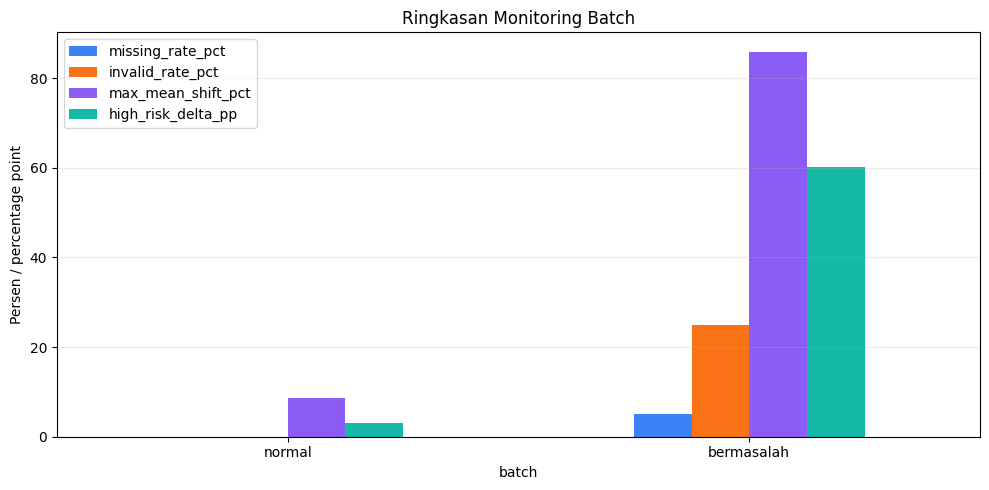

In [16]:
plot_columns = [
    "missing_rate_pct", "invalid_rate_pct",
    "max_mean_shift_pct", "high_risk_delta_pp"
]
ax = reports.set_index("batch")[plot_columns].plot(
    kind="bar", figsize=(10, 5), color=["#3B82F6", "#F97316", "#8B5CF6", "#14B8A6"]
)
ax.set_title("Ringkasan Monitoring Batch")
ax.set_ylabel("Persen / percentage point")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("grafik_monitoring_hari3.png", dpi=160)
plt.show()


## Bagian K — Catat dan tangani insiden

Pada latihan ini kita mengarantina batch bermasalah dan meminta batch koreksi dari sumber data. Jangan diam-diam mengubah data tanpa persetujuan.


### 📘 Penjelasan — Mencatat insiden
**Apa yang dilakukan:** mengisi log insiden untuk batch bermasalah.
**Penjelasan:** log insiden seperti buku laporan kejadian: nomor insiden, gejala, dampak, tindakan sementara (**karantina batch**), dugaan akar masalah, pemilik, dan cara verifikasi. Prinsipnya, **jangan diam-diam mengubah data agar terlihat hijau**; batch dikarantina dan koreksi diminta dari sumber data.
**Hasil yang benar:** satu baris `INC-H3-001` dengan `status_awal` MERAH.

In [17]:
incident_log = pd.read_csv("template_log_insiden_hari3.csv", dtype="string")
incident_log.loc[0] = {
    "incident_id": "INC-H3-001",
    "tanggal": pd.Timestamp.today().date().isoformat(),
    "batch": "bermasalah",
    "status_awal": report_problem["status"],
    "gejala": "missing, nilai di luar rentang, kategori Weekly",
    "dampak": "prediksi batch tidak boleh dipakai",
    "tindakan_sementara": "karantina batch dan gunakan artefak terakhir yang tervalidasi",
    "akar_masalah": "kontrak data sumber berubah tanpa handoff",
    "tindakan_permanen": "perbaiki sumber data dan tambah validasi sebelum prediksi",
    "pemilik": "Data Owner + ML Owner",
    "verifikasi": "jalankan pemeriksaan pada batch perbaikan",
}
incident_log


,incident_id,tanggal,batch,status_awal,gejala,dampak,tindakan_sementara,akar_masalah,tindakan_permanen,pemilik,verifikasi,status_akhir,bukti
0,INC-H3-001,2026-11-11,bermasalah,MERAH,"missing, nilai di luar rentang, kategori Weekly",prediksi batch tidak boleh dipakai,karantina batch dan gunakan artefak terakhir y...,kontrak data sumber berubah tanpa handoff,perbaiki sumber data dan tambah validasi sebel...,Data Owner + ML Owner,jalankan pemeriksaan pada batch perbaikan,<NA>,<NA>


## Bagian L — Verifikasi batch perbaikan


### 📘 Penjelasan — Memverifikasi batch perbaikan
**Apa yang dilakukan:** memeriksa batch koreksi dengan fungsi yang sama.
**Penjelasan:** batch perbaikan diperlakukan sebagai batch baru dan harus lolos semua pemeriksaan. Insiden ditutup berdasarkan **bukti sebelum dan sesudah**: MERAH (60/80 valid) menjadi HIJAU (80/80 valid).
**Hasil yang benar:** status **HIJAU**, valid 80 dari 80, data kosong 0%, tidak valid 0%, kategori asing 0.
**Kalau berbeda:** jangan menutup insiden kalau belum hijau.

In [18]:
report_fixed = check_batch(batch_fixed, "perbaikan")
pd.Series(report_fixed)


batch                    perbaikan
status                       HIJAU
rows                            80
valid_rows                      80
missing_rate_pct               0.0
invalid_rate_pct               0.0
unseen_category_count            0
max_mean_shift_pct            9.52
high_risk_rate_pct           46.25
high_risk_delta_pp            8.13
accuracy                     0.812
recall                       0.824
accuracy_drop                0.031
dtype: object

Hasil acuan: **status HIJAU**. Insiden baru dapat ditutup setelah bukti pemeriksaan disimpan.


### 📘 Penjelasan — Menyimpan laporan dan log insiden
**Apa yang dilakukan:** menutup log insiden lalu menyimpan semua bukti.
**Penjelasan:** `status_akhir` baru ditulis setelah hasil verifikasi ada. Laporan ketiga batch disimpan dalam dua format (CSV dan JSON), dan log insiden disimpan sebagai file terisi.
**Hasil yang benar:** empat baris `Tersimpan:` (laporan CSV, laporan JSON, log insiden, grafik).

In [19]:
incident_log.loc[0, "status_akhir"] = report_fixed["status"]
incident_log.loc[0, "bukti"] = "laporan_monitoring_hari3.csv + grafik_monitoring_hari3.png"

all_reports = pd.DataFrame([report_normal, report_problem, report_fixed])
all_reports.to_csv("laporan_monitoring_hari3.csv", index=False)
Path("laporan_monitoring_hari3.json").write_text(
    json.dumps(all_reports.to_dict(orient="records"), indent=2), encoding="utf-8"
)
incident_log.to_csv("log_insiden_hari3_terisi.csv", index=False)

print("Tersimpan: laporan_monitoring_hari3.csv")
print("Tersimpan: laporan_monitoring_hari3.json")
print("Tersimpan: log_insiden_hari3_terisi.csv")
print("Tersimpan: grafik_monitoring_hari3.png")


Tersimpan: laporan_monitoring_hari3.csv
Tersimpan: laporan_monitoring_hari3.json
Tersimpan: log_insiden_hari3_terisi.csv
Tersimpan: grafik_monitoring_hari3.png


## Bagian M — Unduh bukti akhir


### 📘 Penjelasan — Mengunduh bukti akhir
**Apa yang dilakukan:** mengunduh kelima file bukti.
**Penjelasan:** rencana terisi, laporan CSV, laporan JSON, grafik, dan log insiden. Kalau browser menanyakan izin unduh banyak file, pilih **Allow**. Simpan bersama notebook dan screenshot di folder Sesi 3.
**Hasil yang benar:** lima file terunduh. Setelah itu tutup runtime.

In [20]:
from google.colab import files

OUTPUT_FILES = [
    "rencana_perawatan_hari3_terisi.csv",
    "laporan_monitoring_hari3.csv",
    "laporan_monitoring_hari3.json",
    "log_insiden_hari3_terisi.csv",
    "grafik_monitoring_hari3.png",
]

for name in OUTPUT_FILES:
    files.download(name)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Selesai

Anda telah menjalankan satu siklus perawatan: **rencanakan → ukur → deteksi → tangani → verifikasi → simpan bukti**.
